<a href="https://colab.research.google.com/github/kirtheeshj/Aiml-assignment-/blob/main/WeatherForecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The file is already available in the runtime, so we can define the path directly as a string
filename = "/content/open-meteo-11.35N77.74E174m.csv"

# Find the actual CSV header (Open-Meteo may include metadata rows)
with open(filename, "r", encoding="utf-8") as f:
    lines = f.readlines()

header_row = next(
    i for i, line in enumerate(lines)
    if "time" in line and "temperature_2m_mean" in line
)

df = pd.read_csv(filename, skiprows=header_row)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
display(df.tail())

Dataset shape: (1461, 7)
Columns: ['time', 'temperature_2m_mean (°C)', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'relative_humidity_2m_mean (%)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)']


,time,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),relative_humidity_2m_mean (%),precipitation_sum (mm),wind_speed_10m_max (km/h)
0,2021-01-01,24.0,30.0,19.5,75,0.0,16.2
1,2021-01-02,23.9,29.3,18.7,76,0.8,13.7
2,2021-01-03,23.7,27.4,21.1,86,7.1,7.4
3,2021-01-04,24.6,27.9,22.2,82,0.7,14.5
4,2021-01-05,24.8,30.4,21.3,82,5.8,13.0


,time,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),relative_humidity_2m_mean (%),precipitation_sum (mm),wind_speed_10m_max (km/h)
1456,2024-12-27,25.6,31.0,22.3,81,9.4,11.1
1457,2024-12-28,25.7,30.8,21.5,75,0.1,13.4
1458,2024-12-29,26.5,31.8,21.7,68,0.0,12.9
1459,2024-12-30,26.4,31.5,22.7,72,2.5,16.0
1460,2024-12-31,26.5,32.0,22.2,66,0.0,15.9


In [4]:
# Rename the date column to match our project code
df = df.rename(columns={"time": "date"})

# Strip units in parentheses (e.g. " (°C)", " (mm)") from columns to match required_columns
df.columns = df.columns.str.replace(r"\s*\(.*\)", "", regex=True)

required_columns = [
    "date",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_max"
]

# Check required columns
missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

df = df[required_columns].copy()

# Convert date and weather measurements
df["date"] = pd.to_datetime(df["date"], errors="coerce")

for col in required_columns[1:]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort chronologically and remove duplicate dates
df = df.dropna(subset=["date"])
df = df.sort_values("date")
df = df.drop_duplicates(subset="date")
df = df.set_index("date")

# Make sure each calendar day has a row
df = df.asfreq("D")

# Convert infinite values to missing values
df = df.replace([np.inf, -np.inf], np.nan)

# Fill missing values using time interpolation
df = df.interpolate(method="time", limit=3)

# Remove remaining missing rows
df = df.dropna()

print("Cleaned records:", len(df))
print("Start date:", df.index.min())
print("End date:", df.index.max())
print("Missing values:\n", df.isnull().sum())

# Check that the observations are daily and consecutive
print("Daily frequency:", df.index.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all())

if len(df) < 1000:
    raise ValueError("You need at least 1000 valid daily records.")

Cleaned records: 1461
Start date: 2021-01-01 00:00:00
End date: 2024-12-31 00:00:00
Missing values:
 temperature_2m_mean          0
temperature_2m_max           0
temperature_2m_min           0
relative_humidity_2m_mean    0
precipitation_sum            0
wind_speed_10m_max           0
dtype: int64
Daily frequency: True


In [5]:

features = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_max"
]

target = "temperature_2m_mean"

data = df[features].copy()

# Use the first 80% of dates for training
train_end = int(len(data) * 0.80)

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Fit only on the training dates
scaler.fit(data.iloc[:train_end])

scaled_data = scaler.transform(data)

print("Features normalized.")
print("Training records:", train_end)
print("Testing records:", len(data) - train_end)


Features normalized.
Training records: 1168
Testing records: 293


In [6]:

window_size = 30
target_index = features.index(target)

X = []
y = []
target_positions = []

for i in range(window_size, len(scaled_data)):
    X.append(scaled_data[i-window_size:i])
    y.append(scaled_data[i, target_index])
    target_positions.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_positions = np.array(target_positions)

# Assign sequences by the date being predicted
train_mask = target_positions < train_end
test_mask = target_positions >= train_end

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

test_dates = data.index[target_positions[test_mask]]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (1138, 30, 6)
y_train shape: (1138,)
X_test shape: (293, 30, 6)
y_test shape: (293,)


In [7]:

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
np.random.seed(42)

model = Sequential([
    LSTM(64, input_shape=(window_size, len(features))),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,289 (79.25 KB)

 Trainable params: 20,289 (79.25 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0686 - val_loss: 0.0084
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0143 - val_loss: 0.0068
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0107 - val_loss: 0.0052
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0099 - val_loss: 0.0050
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0099 - val_loss: 0.0044
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0088 - val_loss: 0.0043
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0087 - val_loss: 0.0040
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0083 - val_loss: 0.0041
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0078 - val_loss: 0.0040
Epoch 10/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0075 - val_loss: 0.0042
Epoch 11/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0085 - val_loss: 0.0040
Epoch 12/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0

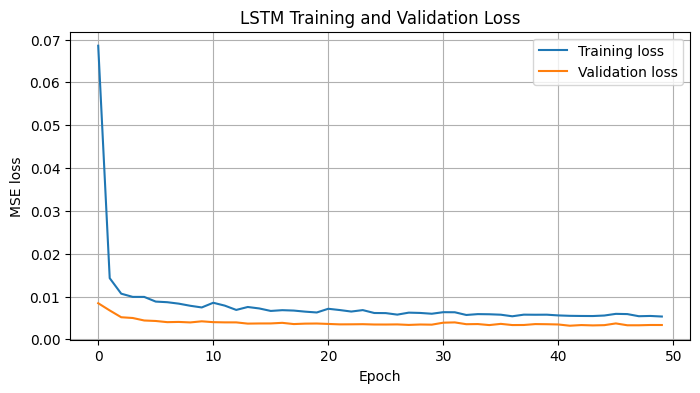

In [9]:

plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict normalized temperatures
y_pred_scaled = model.predict(X_test)

# Reverse MinMax normalization for the target variable
target_min = scaler.data_min_[target_index]
target_max = scaler.data_max_[target_index]

y_actual = y_test * (target_max - target_min) + target_min
y_pred = y_pred_scaled.flatten() * (target_max - target_min) + target_min

mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

print(f"MAE:  {mae:.2f} °C")
print(f"RMSE: {rmse:.2f} °C")


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
MAE:  0.59 °C
RMSE: 0.75 °C


In [15]:
# Prediction accuracy based on relative absolute error
accuracy = 100 * (1 - np.mean(
    np.abs(y_actual - y_pred) / np.maximum(np.abs(y_actual), 1e-8)
))

print(f"Prediction Accuracy: {accuracy:.2f}%")
print(f"MAE: {mae:.2f} °C")
print(f"RMSE: {rmse:.2f} °C")

Prediction Accuracy: 97.89%
MAE: 0.59 °C
RMSE: 0.75 °C


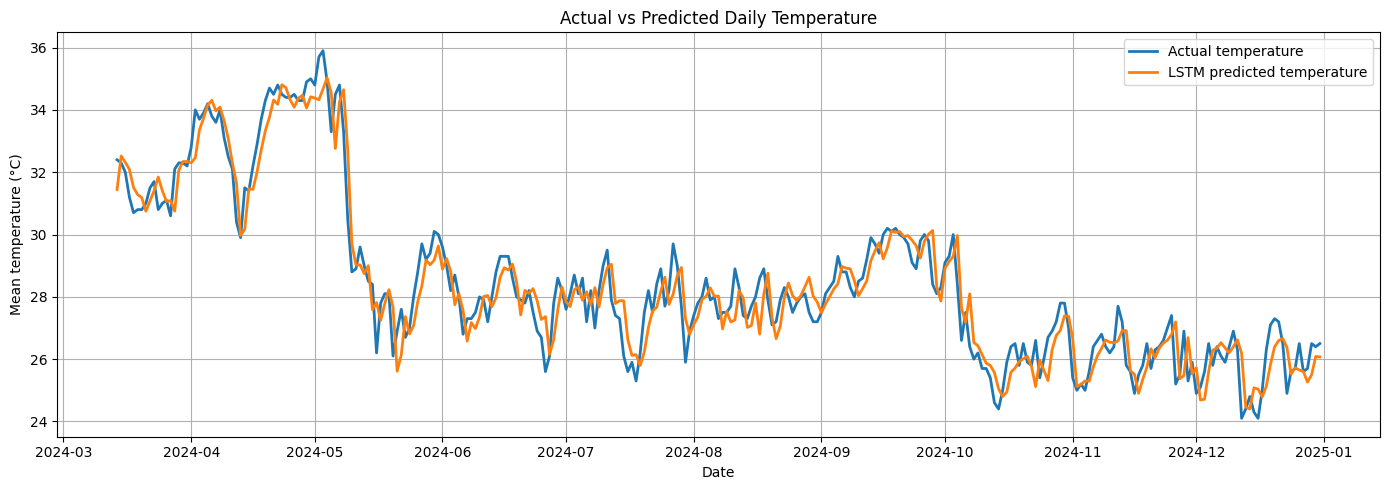

In [11]:

plt.figure(figsize=(14, 5))

plt.plot(
    test_dates,
    y_actual,
    label="Actual temperature",
    linewidth=2
)

plt.plot(
    test_dates,
    y_pred,
    label="LSTM predicted temperature",
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("Mean temperature (°C)")
plt.title("Actual vs Predicted Daily Temperature")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [12]:

# Start with the last 30 days of observed weather
current_sequence = scaled_data[-window_size:].copy()

future_predictions = []
future_dates = []

last_date = data.index[-1]

for day in range(1, 8):
    # Predict next day's normalized mean temperature
    next_temp_scaled = model.predict(
        current_sequence[np.newaxis, :, :],
        verbose=0
    )[0, 0]

    # Convert prediction back to Celsius
    next_temp = (
        next_temp_scaled * (target_max - target_min)
        + target_min
    )

    future_date = last_date + pd.Timedelta(days=day)

    future_predictions.append(next_temp)
    future_dates.append(future_date)

    # Construct next day's feature row.
    # Other weather variables are held at their latest values.
    next_row = current_sequence[-1].copy()
    next_row[target_index] = next_temp_scaled

    # Slide the 30-day window forward
    current_sequence = np.vstack([
        current_sequence[1:],
        next_row
    ])

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecast_mean_temperature_C": future_predictions
})

display(forecast_df.round(2))


,Date,Forecast_mean_temperature_C
0,2025-01-01,26.42
1,2025-01-02,26.55
2,2025-01-03,26.66
3,2025-01-04,26.75
4,2025-01-05,26.82
5,2025-01-06,26.87
6,2025-01-07,26.92


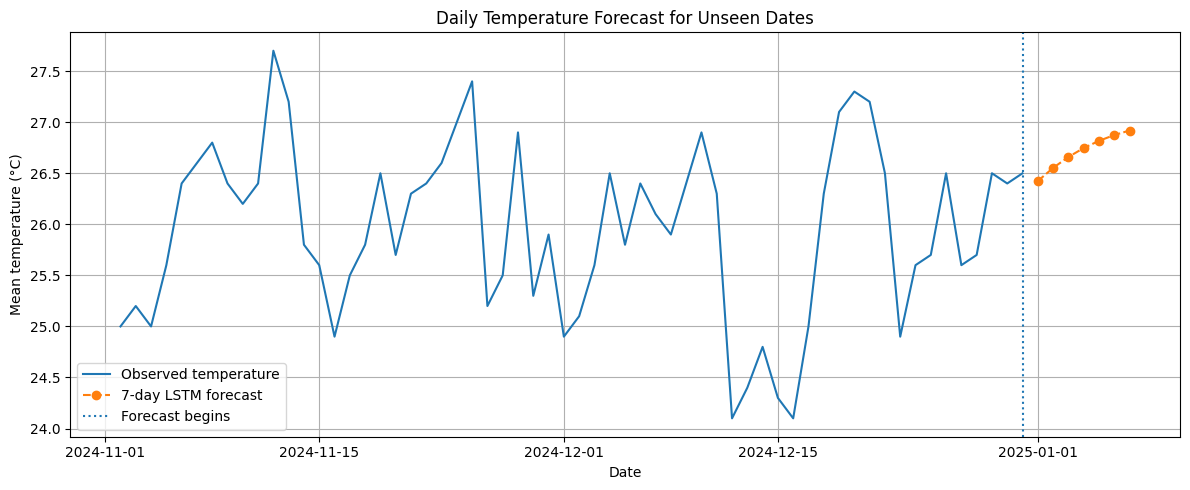

In [13]:

plt.figure(figsize=(12, 5))

# Show recent observed temperatures
recent_days = 60

plt.plot(
    data.index[-recent_days:],
    data[target].iloc[-recent_days:],
    label="Observed temperature"
)

# Show forecasted temperatures
plt.plot(
    future_dates,
    future_predictions,
    marker="o",
    linestyle="--",
    label="7-day LSTM forecast"
)

plt.axvline(
    data.index[-1],
    linestyle=":",
    label="Forecast begins"
)

plt.xlabel("Date")
plt.ylabel("Mean temperature (°C)")
plt.title("Daily Temperature Forecast for Unseen Dates")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [14]:

# Today's temperature as tomorrow's prediction
baseline_scaled = scaled_data[target_positions[test_mask] - 1, target_index]

baseline_pred = (
    baseline_scaled * (target_max - target_min)
    + target_min
)

baseline_mae = mean_absolute_error(y_actual, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_actual, baseline_pred))

print("LSTM:")
print(f"MAE: {mae:.2f} °C")
print(f"RMSE: {rmse:.2f} °C")

print("\nPersistence baseline:")
print(f"MAE: {baseline_mae:.2f} °C")
print(f"RMSE: {baseline_rmse:.2f} °C")


LSTM:
MAE: 0.59 °C
RMSE: 0.75 °C

Persistence baseline:
MAE: 0.59 °C
RMSE: 0.76 °C
